In [115]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [116]:
def modified_euler_method(f, t_span, y0, h, exact_solution=None):
  t0, tf = t_span
  t_values = np.arange(t0, tf+h, h)
  y_values = [y0]
  # Store iteration results for the table
  table_data = {'Iteration': [0], 't': [t0], 'y': [y0]}
  # Modified Euler's Method Iteration (Heun's Method)
  y = y0
  for i, t in enumerate(t_values[:-1]):
    k1 = f(t, y)
    k2 = f(t+h, y+h*k1)
    y += h * (k1+k2) / 2
    y_values.append(y)
    table_data['Iteration'].append(i+1)
    table_data['t'].append(t+h)
    table_data['y'].append(y)
  # Display the solution table
  df = pd.DataFrame(table_data)
  print("Solution Table")
  print(df.to_string(index=False))
  # Plot the numerical solution
  plt.figure(figsize=(10, 5))
  plt.plot(t_values, y_values, label='Modified Euler Solution', marker='o')
  if exact_solution:
    exact_y = [exact_solution(t) for t in t_values]
    plt.plot(t_values, exact_y, label='Exact Solution', linestyle='--')
  plt.xlabel('t')
  plt.ylabel('y')
  plt.title("Modified Euler Method Solution of ODE")
  plt.legend()
  plt.grid(True)
  plt.show()
  # Plot the error if exact solution is provided
  if exact_solution:
    error = np.abs(np.array(y_values) - np.array(exact_y))
    plt.figure(figsize=(10, 5))
    plt.plot(t_values, error, label='Error', color='red')
    plt.xlabel('t')
    plt.ylabel('Error')
    plt.title("Error Plot (Modified Euler Method)")
    plt.legend()
    plt.grid(True)
    plt.show()

In [117]:
# Example Usage
def example_function(t, y):
  # return -2 * y + np.sin(t)
  # return 1 + t * y**2
  return y - t

In [118]:
def exact_solution(t):
  # return (np.sin(t) - np.cos(t)) / 5 + (np.cos(t) + 2 * np.sin(t)) * np.exp(-2 * t) / 5
  return t + 1 + (1/2) * np.exp(t)

In [119]:
t0, tf = 0, 2
y0 = 1.5
step_size = 0.1

Solution Table
 Iteration   t        y
         0 0.0 1.500000
         1 0.1 1.652500
         2 0.2 1.810513
         3 0.3 1.974616
         4 0.4 2.145451
         5 0.5 2.323723
         6 0.6 2.510214
         7 0.7 2.705787
         8 0.8 2.911394
         9 0.9 3.128091
        10 1.0 3.357040
        11 1.1 3.599530
        12 1.2 3.856980
        13 1.3 4.130963
        14 1.4 4.423214
        15 1.5 4.735652
        16 1.6 5.070395
        17 1.7 5.429787
        18 1.8 5.816414
        19 1.9 6.233138
        20 2.0 6.683117


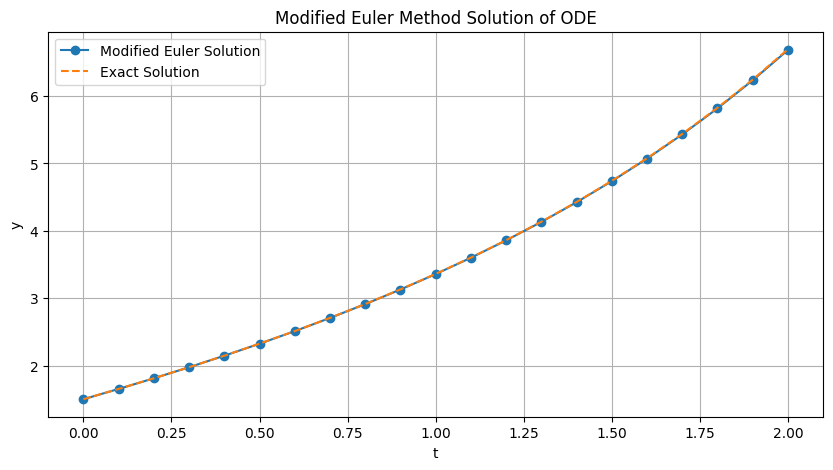

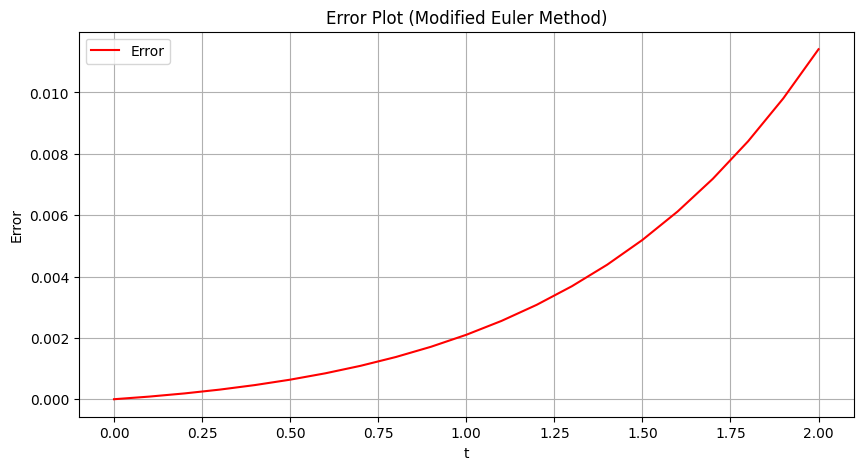

In [120]:
modified_euler_method(example_function, (t0, tf), y0, step_size, exact_solution=exact_solution)    # if exact sol. is known
# modified_euler_method(example_function, (t0, tf), y0, step_size, exact_solution=None)